# Pork rasher packaging inspection: full pipeline
Detect packaging defects with YOLO, then decide tray PASS/FAIL.
Use a **GPU runtime** (Runtime > Change runtime type > T4 GPU) and add a Colab secret named `ROBOFLOW_API_KEY`
(key icon in the left sidebar, with Notebook access switched on).

## 1. Setup

In [1]:
import os, sys, subprocess

REPO_URL = "https://github.com/ElijahKhoury1/pork-rasher-qc.git"
REPO_DIR = "/content/pork-rasher-qc"

# Clone the first time; on later runs just pull the latest code (keeps datasets/ and runs/)
if not os.path.isdir(REPO_DIR):
    r = subprocess.run(["git", "clone", REPO_URL, REPO_DIR], capture_output=True, text=True)
else:
    r = subprocess.run(["git", "-C", REPO_DIR, "pull"], capture_output=True, text=True)
print(r.stdout, r.stderr)

os.chdir(REPO_DIR)
sys.path.insert(0, f"{REPO_DIR}/src")      # lets `import rasher_qc` work without pip install -e
print(sorted(os.listdir("src/rasher_qc")))

# Install dependencies (python -m pip avoids needing a shell)
r = subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "ultralytics", "roboflow", "pandas", "matplotlib"],
                   capture_output=True, text=True)
print("pip exit code:", r.returncode)

 Cloning into '/content/pork-rasher-qc'...

['__init__.py', 'data.py', 'decision.py', 'evaluate.py', 'infer.py', 'leakage.py', 'train.py']
pip exit code: 0


In [2]:
import torch, sys
print("Python", sys.version.split()[0], "| torch", torch.__version__, "| GPU:", torch.cuda.is_available())
SEED = 0

Python 3.13.15 | torch 2.11.0+cu130 | GPU: True


## 2. Download the dataset (Version 4, YOLO format)

In [3]:
from google.colab import userdata
from rasher_qc import data

DATASET = data.download_roboflow(userdata.get("ROBOFLOW_API_KEY"), version=4, location="datasets/pork-rasher")
DATA_YAML = str(DATASET / "data.yaml")
print(DATASET)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to datasets/pork-rasher in yolov8:: 100%|██████████| 7103/7103 [00:01<00:00, 6035.83it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
/content/pork-rasher-qc/datasets/pork-rasher


## 3. Check the data and remove leakage
Augmented copies of one frame must not sit in more than one split, or test scores are inflated.

In [4]:
import pandas as pd
print(data.validate_dataset(DATASET))
counts = pd.DataFrame(data.count_classes(DATASET)).fillna(0).astype(int)
display(counts)
print("Frames appearing in more than one split:", len(data.find_cross_split_leakage(DATASET)))

{'images': {'train': 3349, 'valid': 120, 'test': 80}, 'missing_labels': [], 'bad_class_ids': []}


,train,valid,test
packaging-error,1712,34,23
unsealed,1055,81,49
wrinkle,18,0,0
twisted-meat,72,3,4
loose-meat,66,3,3


Frames appearing in more than one split: 13


In [5]:
# Keep each leaked frame in the highest-priority split (test > valid > train); copies are moved to a backup folder
from rasher_qc.leakage import remove_cross_split_leakage
print("images moved:", remove_cross_split_leakage(DATASET))
print("remaining leaks:", len(data.find_cross_split_leakage(DATASET)))

images moved: 37
remaining leaks: 0


In [6]:
# Tray-level labels per split (FAIL = at least one annotated defect)
from rasher_qc.decision import tray_label_from_yolo_txt
names = data.class_names(DATASET)
rows = []
for split in ["train", "valid", "test"]:
    labels = [tray_label_from_yolo_txt(data.label_path_for(p), names) for p in data.list_images(DATASET, split)]
    rows.append({"split": split, "images": len(labels), "FAIL": labels.count("FAIL"), "PASS": labels.count("PASS")})
display(pd.DataFrame(rows).set_index("split"))
display(pd.DataFrame(data.count_classes(DATASET)).fillna(0).astype(int))

,images,FAIL,PASS
split,,,
train,3313,2629,684
valid,119,105,14
test,80,68,12


,train,valid,test
packaging-error,1679,34,23
unsealed,1052,80,49
wrinkle,18,0,0
twisted-meat,72,3,4
loose-meat,66,3,3


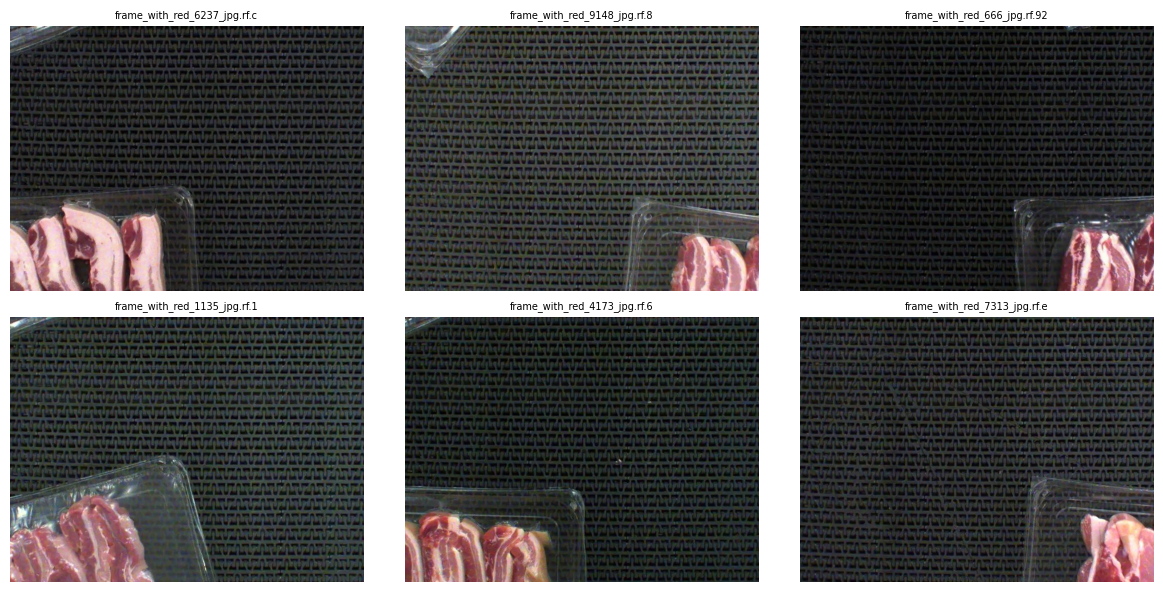

In [7]:
# Look at a few images
import random, matplotlib.pyplot as plt, matplotlib.image as mpimg
random.seed(SEED)
files = random.sample(data.list_images(DATASET, "train"), 6)
fig, axs = plt.subplots(2, 3, figsize=(12, 6))
for ax, f in zip(axs.ravel(), files):
    ax.imshow(mpimg.imread(f)); ax.set_title(f.name[:28], fontsize=7); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Train: baseline and alternatives
Baseline = `yolov8n` at 640 px. Alternatives vary model size and input resolution.
Selection uses the **validation** split only. Early stopping (`patience`) ends a run when validation stops improving.

In [8]:
from rasher_qc import train, evaluate

EXPERIMENTS = {
    "baseline_n_640": dict(weights="yolov8n.pt", imgsz=640),
    "s_640":          dict(weights="yolov8s.pt", imgsz=640),
    "n_416":          dict(weights="yolov8n.pt", imgsz=416),
}
EPOCHS = 3   # use 3 for a quick smoke test

for name, cfg in EXPERIMENTS.items():
    train.train(DATA_YAML, epochs=EPOCHS, seed=SEED, name=name, patience=8, **cfg)
    print("finished", name)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pork-rasher-qc/datasets/pork-rasher/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_n_640, nbs=64, nms=None, ops

In [10]:
# Find where Ultralytics saved each run's best weights (the folder differs between versions)
import glob
found = glob.glob("/content/**/best.pt", recursive=True)
best = {}
for name in EXPERIMENTS:
    matches = [f for f in found if f"/{name}/weights/best.pt" in f]
    if matches:
        best[name] = matches[0]
    else:
        print("WARNING: no weights found for", name)
print(best)

{'baseline_n_640': '/content/pork-rasher-qc/runs/detect/runs/baseline_n_640/weights/best.pt', 's_640': '/content/pork-rasher-qc/runs/detect/runs/s_640/weights/best.pt', 'n_416': '/content/pork-rasher-qc/runs/detect/runs/n_416/weights/best.pt'}


## 5. Compare on the validation split (model selection)

In [11]:
import time
import numpy as np
from ultralytics import YOLO
from ultralytics.utils.torch_utils import get_flops

def benchmark_latency(weights, images, imgsz=640, warmup=5, runs=50):
    # Latency, parameters and GFLOPs (this notebook's own copy; counts parameters directly)
    model = YOLO(str(weights))
    imgs = [str(i) for i in images]
    for i in range(warmup):
        model.predict(imgs[i % len(imgs)], imgsz=imgsz, verbose=False)
    times = []
    for i in range(runs):
        t0 = time.perf_counter()
        model.predict(imgs[i % len(imgs)], imgsz=imgsz, verbose=False)
        times.append((time.perf_counter() - t0) * 1000)
    params = sum(p.numel() for p in model.model.parameters())
    try:
        gflops = float(get_flops(model.model, imgsz))
    except Exception:
        gflops = float("nan")
    return {"mean_ms": float(np.mean(times)), "p95_ms": float(np.percentile(times, 95)),
            "fps": float(1000 / np.mean(times)), "params_m": params / 1e6, "gflops": gflops}

rows = []
for name, cfg in EXPERIMENTS.items():
    if name not in best:
        print("skipping", name); continue
    m = evaluate.detection_metrics(best[name], DATA_YAML, split="val", imgsz=cfg["imgsz"])
    imgs = data.list_images(DATASET, "valid")[:20]
    b = benchmark_latency(best[name], imgs, imgsz=cfg["imgsz"])
    rows.append({"model": name, "mAP50": m["map50"], "mAP50-95": m["map50_95"],
                 "precision": m["precision"], "recall": m["recall"],
                 "latency_ms": b["mean_ms"], "fps": b["fps"], "params_M": b["params_m"], "GFLOPs": b["gflops"]})
results = pd.DataFrame(rows).set_index("model").round(3)
display(results)
results.to_csv("experiment_results.csv")
SELECTED = results["mAP50-95"].idxmax()
print("Selected on validation mAP50-95:", SELECTED)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2162.8±933.0 MB/s, size: 66.2 KB)
val: Scanning /content/pork-rasher-qc/datasets/pork-rasher/valid/labels.cache... 119 images, 14 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 119/119 41.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.0it/s 2.7s
                   all        119        120      0.766      0.286      0.315       0.17
Speed: 3.0ms preprocess, 5.6ms inference, 0.0ms loss, 2.5ms postprocess per image
Results saved to /content/pork-rasher-qc/runs/detect/val
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,519 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2564.4±811.5 MB/s, siz

,mAP50,mAP50-95,precision,recall,latency_ms,fps,params_M,GFLOPs
model,,,,,,,,
baseline_n_640,0.315,0.170,0.766,0.286,11.696,85.498,3.139,8.754
s_640,0.318,0.165,0.753,0.263,15.733,63.561,11.138,28.651
n_416,0.279,0.167,0.775,0.303,10.435,95.831,3.139,3.699


Selected on validation mAP50-95: baseline_n_640


## 6. Final test-set evaluation (selected model only, run once)
Detection metrics, per-class AP, and the tray-level PASS/FAIL result. The test set is small and skewed
towards FAIL trays, so also report specificity and the always-FAIL baseline.

In [12]:
cfg = EXPERIMENTS[SELECTED]
final = evaluate.detection_metrics(best[SELECTED], DATA_YAML, split="test", imgsz=cfg["imgsz"])
print({k: round(v, 3) for k, v in final.items() if k != "per_class_map50_95"})
display(pd.Series(final["per_class_map50_95"], name="AP50-95").round(3).to_frame())

# Tray-level decision. Change FAIL_CLASSES if some classes should not cause a reject (None = all).
FAIL_CLASSES = None
tray = evaluate.tray_level_metrics(best[SELECTED], DATASET, split="test", conf=0.25,
                                   imgsz=cfg["imgsz"], fail_classes=FAIL_CLASSES)
print(tray)

n_pass = tray["tn"] + tray["fp"]
n_fail = tray["tp"] + tray["fn"]
spec = tray["tn"] / n_pass if n_pass else float("nan")
print(f"Good trays correctly passed (specificity): {spec:.3f} ({tray['tn']}/{n_pass})")
print(f"Defective trays caught (recall): {tray['recall']:.3f} ({tray['tp']}/{n_fail})")
print(f"Always-FAIL baseline: accuracy {n_fail/(n_fail+n_pass):.3f}, specificity 0.000")

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2425.0±669.8 MB/s, size: 66.0 KB)
val: Scanning /content/pork-rasher-qc/datasets/pork-rasher/test/labels... 80 images, 12 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 80/80 2.1Kit/s 0.0s
val: New cache created: /content/pork-rasher-qc/datasets/pork-rasher/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.3it/s 2.2s
                   all         80         79      0.762      0.284      0.331      0.163
Speed: 5.1ms preprocess, 4.5ms inference, 0.0ms loss, 4.4ms postprocess per image
Results saved to /content/pork-rasher-qc/runs/detect/val-4
{'map50': 0.331, 'map50_95': 0.163, 'precision': 0.762, 'recall': 0.284}


,AP50-95
loose-meat,0.067
packaging-error,0.090
twisted-meat,0.000
unsealed,0.497


{'tp': 46, 'fp': 1, 'fn': 22, 'tn': 11, 'precision': 0.9787234042553191, 'recall': 0.6764705882352942, 'f1': 0.8, 'accuracy': 0.7125}
Good trays correctly passed (specificity): 0.917 (11/12)
Defective trays caught (recall): 0.676 (46/68)
Always-FAIL baseline: accuracy 0.850, specificity 0.000


## 7. Sensitivity: confidence threshold
The threshold trades missed defects (recall) against false rejects (precision).

,precision,recall,f1
conf,,,
0.10,0.968,0.897,0.931
0.20,0.981,0.750,0.850
0.25,0.979,0.676,0.800
0.30,0.977,0.632,0.768
0.40,0.976,0.588,0.734
0.50,0.974,0.544,0.698
0.60,0.971,0.485,0.647


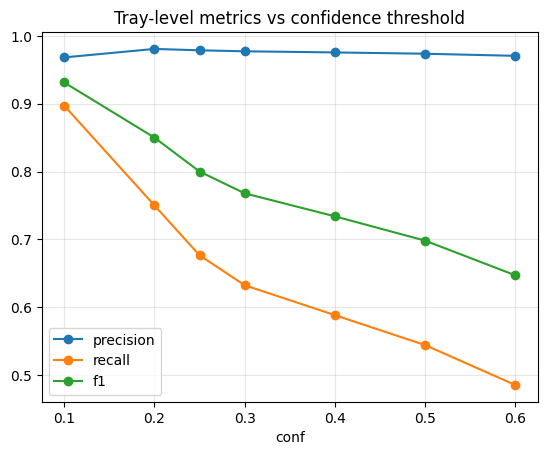

In [13]:
sens = []
for c in [0.1, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6]:
    t = evaluate.tray_level_metrics(best[SELECTED], DATASET, split="test", conf=c,
                                    imgsz=cfg["imgsz"], fail_classes=FAIL_CLASSES)
    sens.append({"conf": c, "precision": t["precision"], "recall": t["recall"], "f1": t["f1"]})
sens = pd.DataFrame(sens).set_index("conf")
display(sens.round(3))
sens.plot(marker="o", title="Tray-level metrics vs confidence threshold"); plt.grid(alpha=.3); plt.show()

## 8. Inspect individual trays and look at failures

In [14]:
from rasher_qc.infer import inspect_tray
model = YOLO(str(best[SELECTED]))
for img in data.list_images(DATASET, "test")[:5]:
    r = inspect_tray(model, img, conf=0.25, imgsz=cfg["imgsz"], fail_classes=FAIL_CLASSES)
    print(img.name[:30], r["status"], r["counts"])

frame_with_red_102_jpg.rf.1016 FAIL {'unsealed': 2}
frame_with_red_121_jpg.rf.ad75 PASS {}
frame_with_red_1271_jpg.rf.fe7 FAIL {'unsealed': 1}
frame_with_red_1298_jpg.rf.bbe PASS {}
frame_with_red_1405_jpg.rf.061 FAIL {'unsealed': 1}


runs/detect/val-4


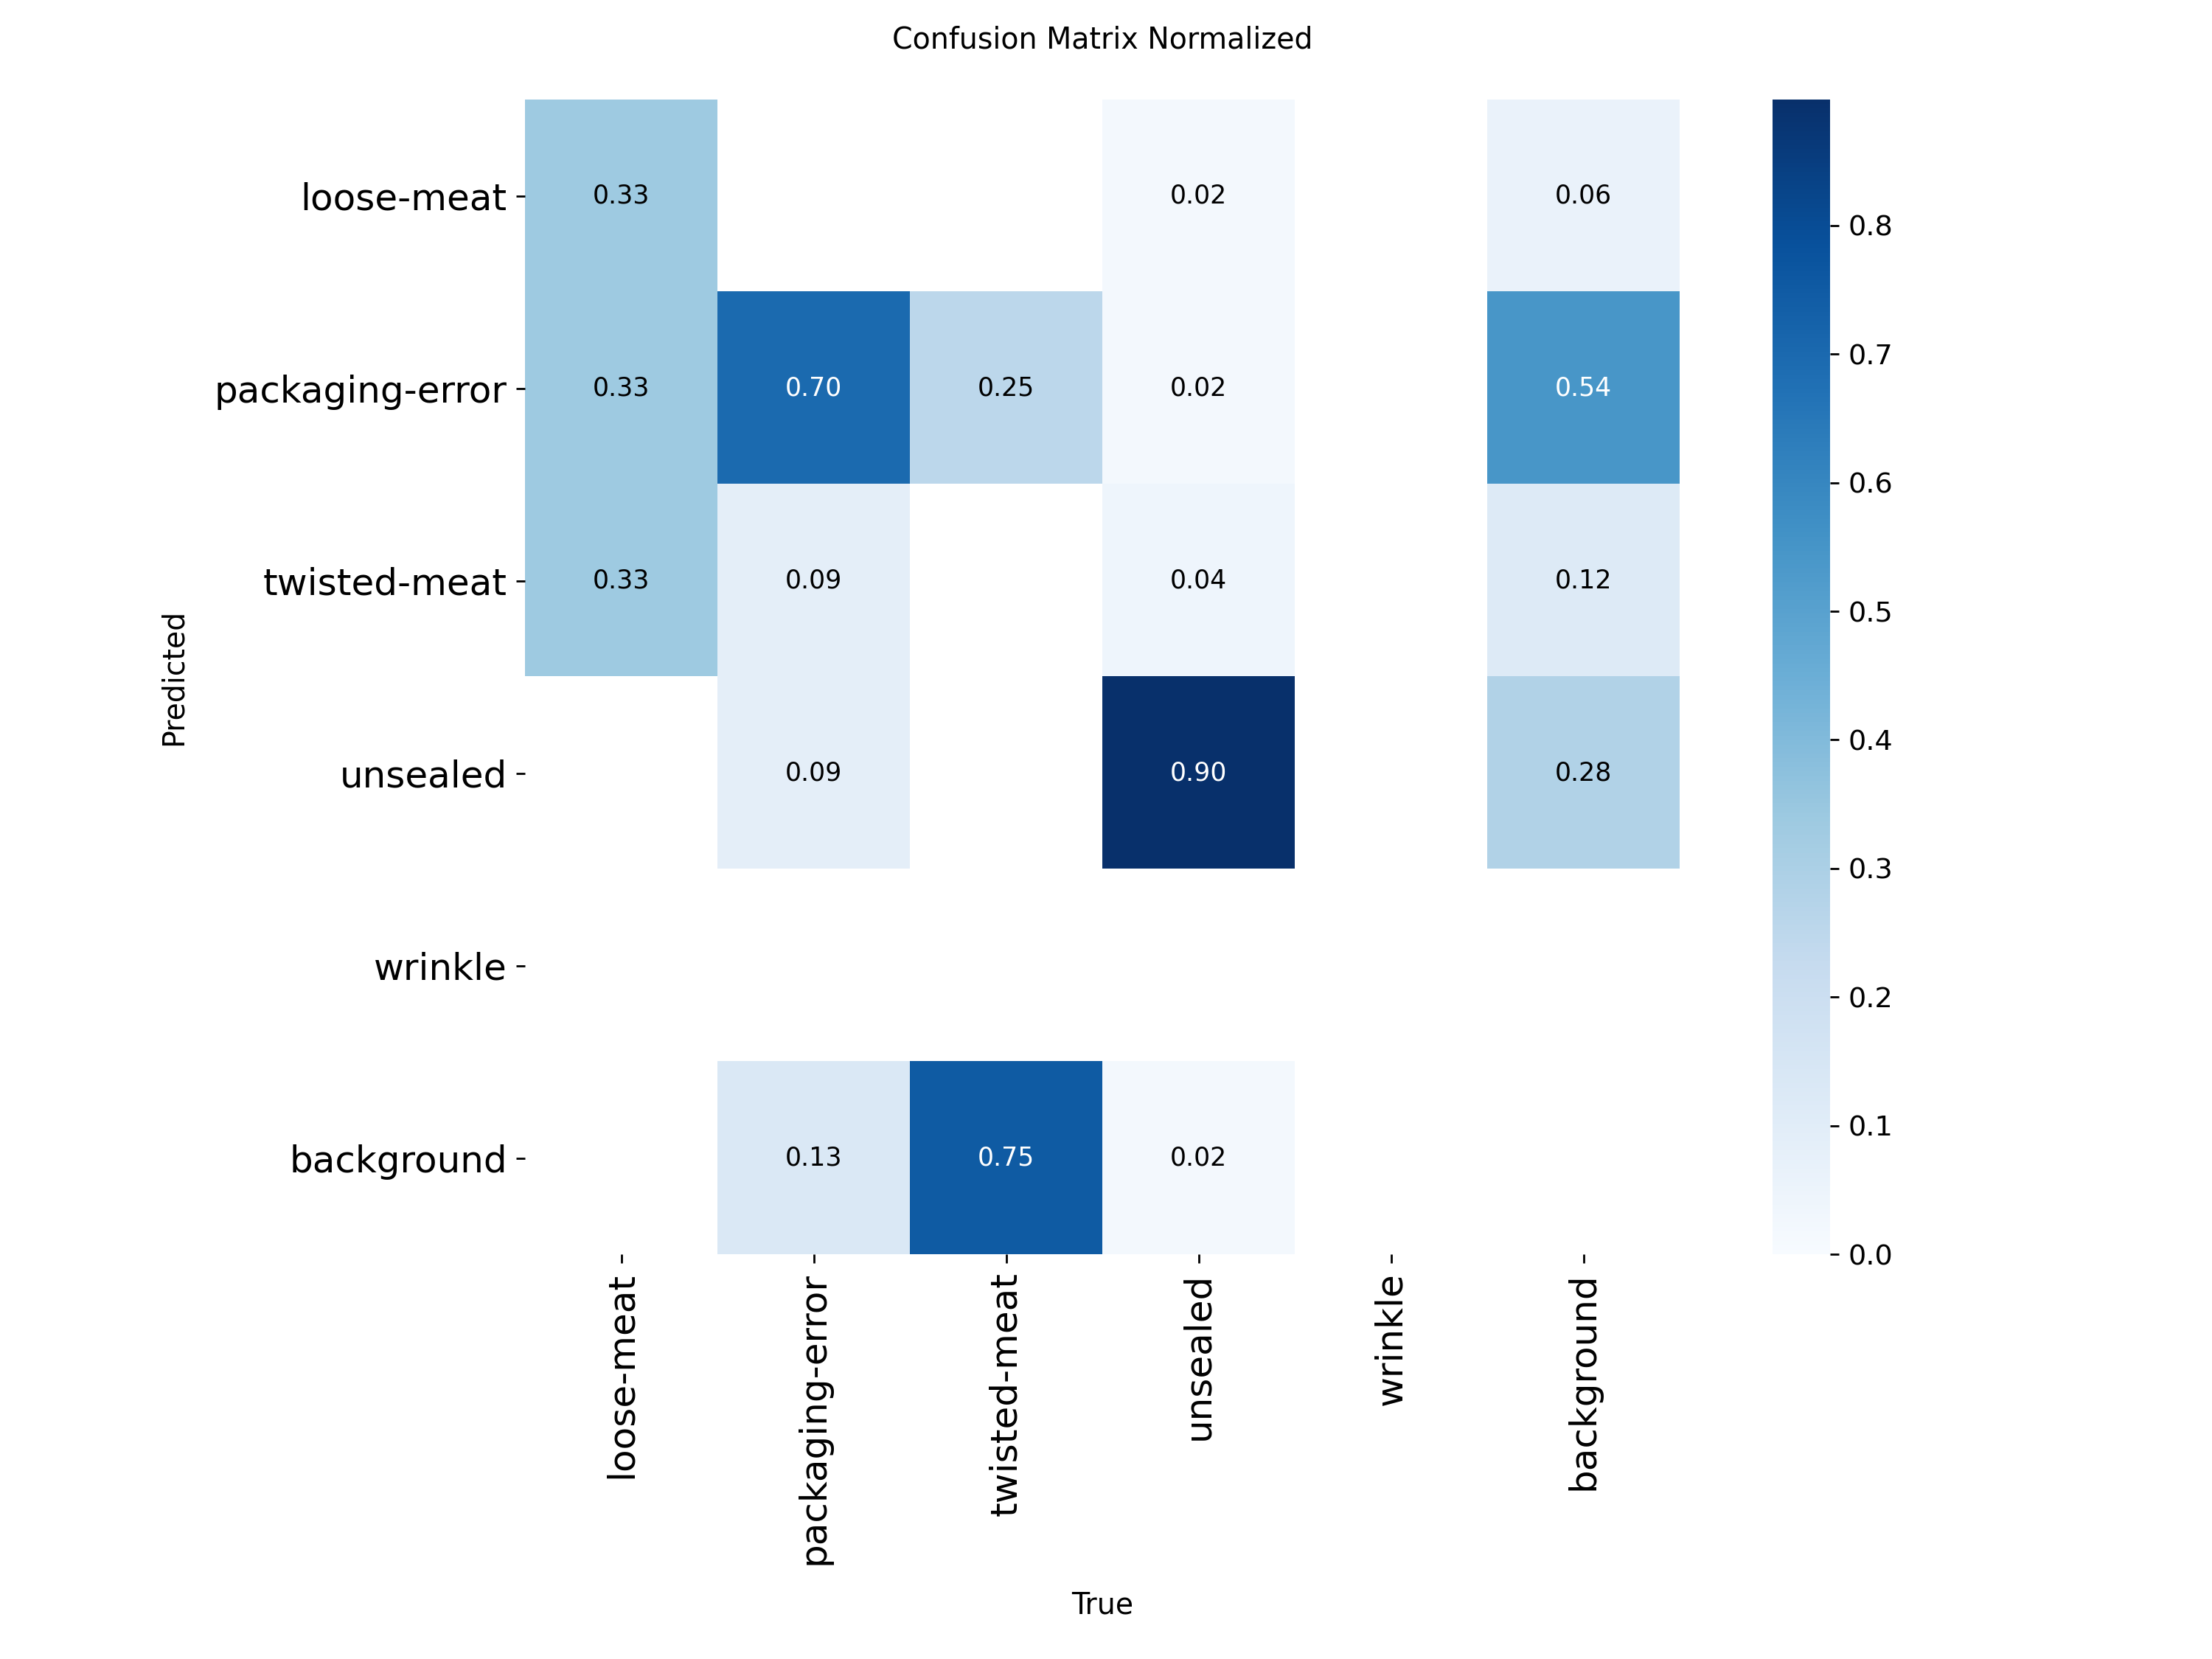

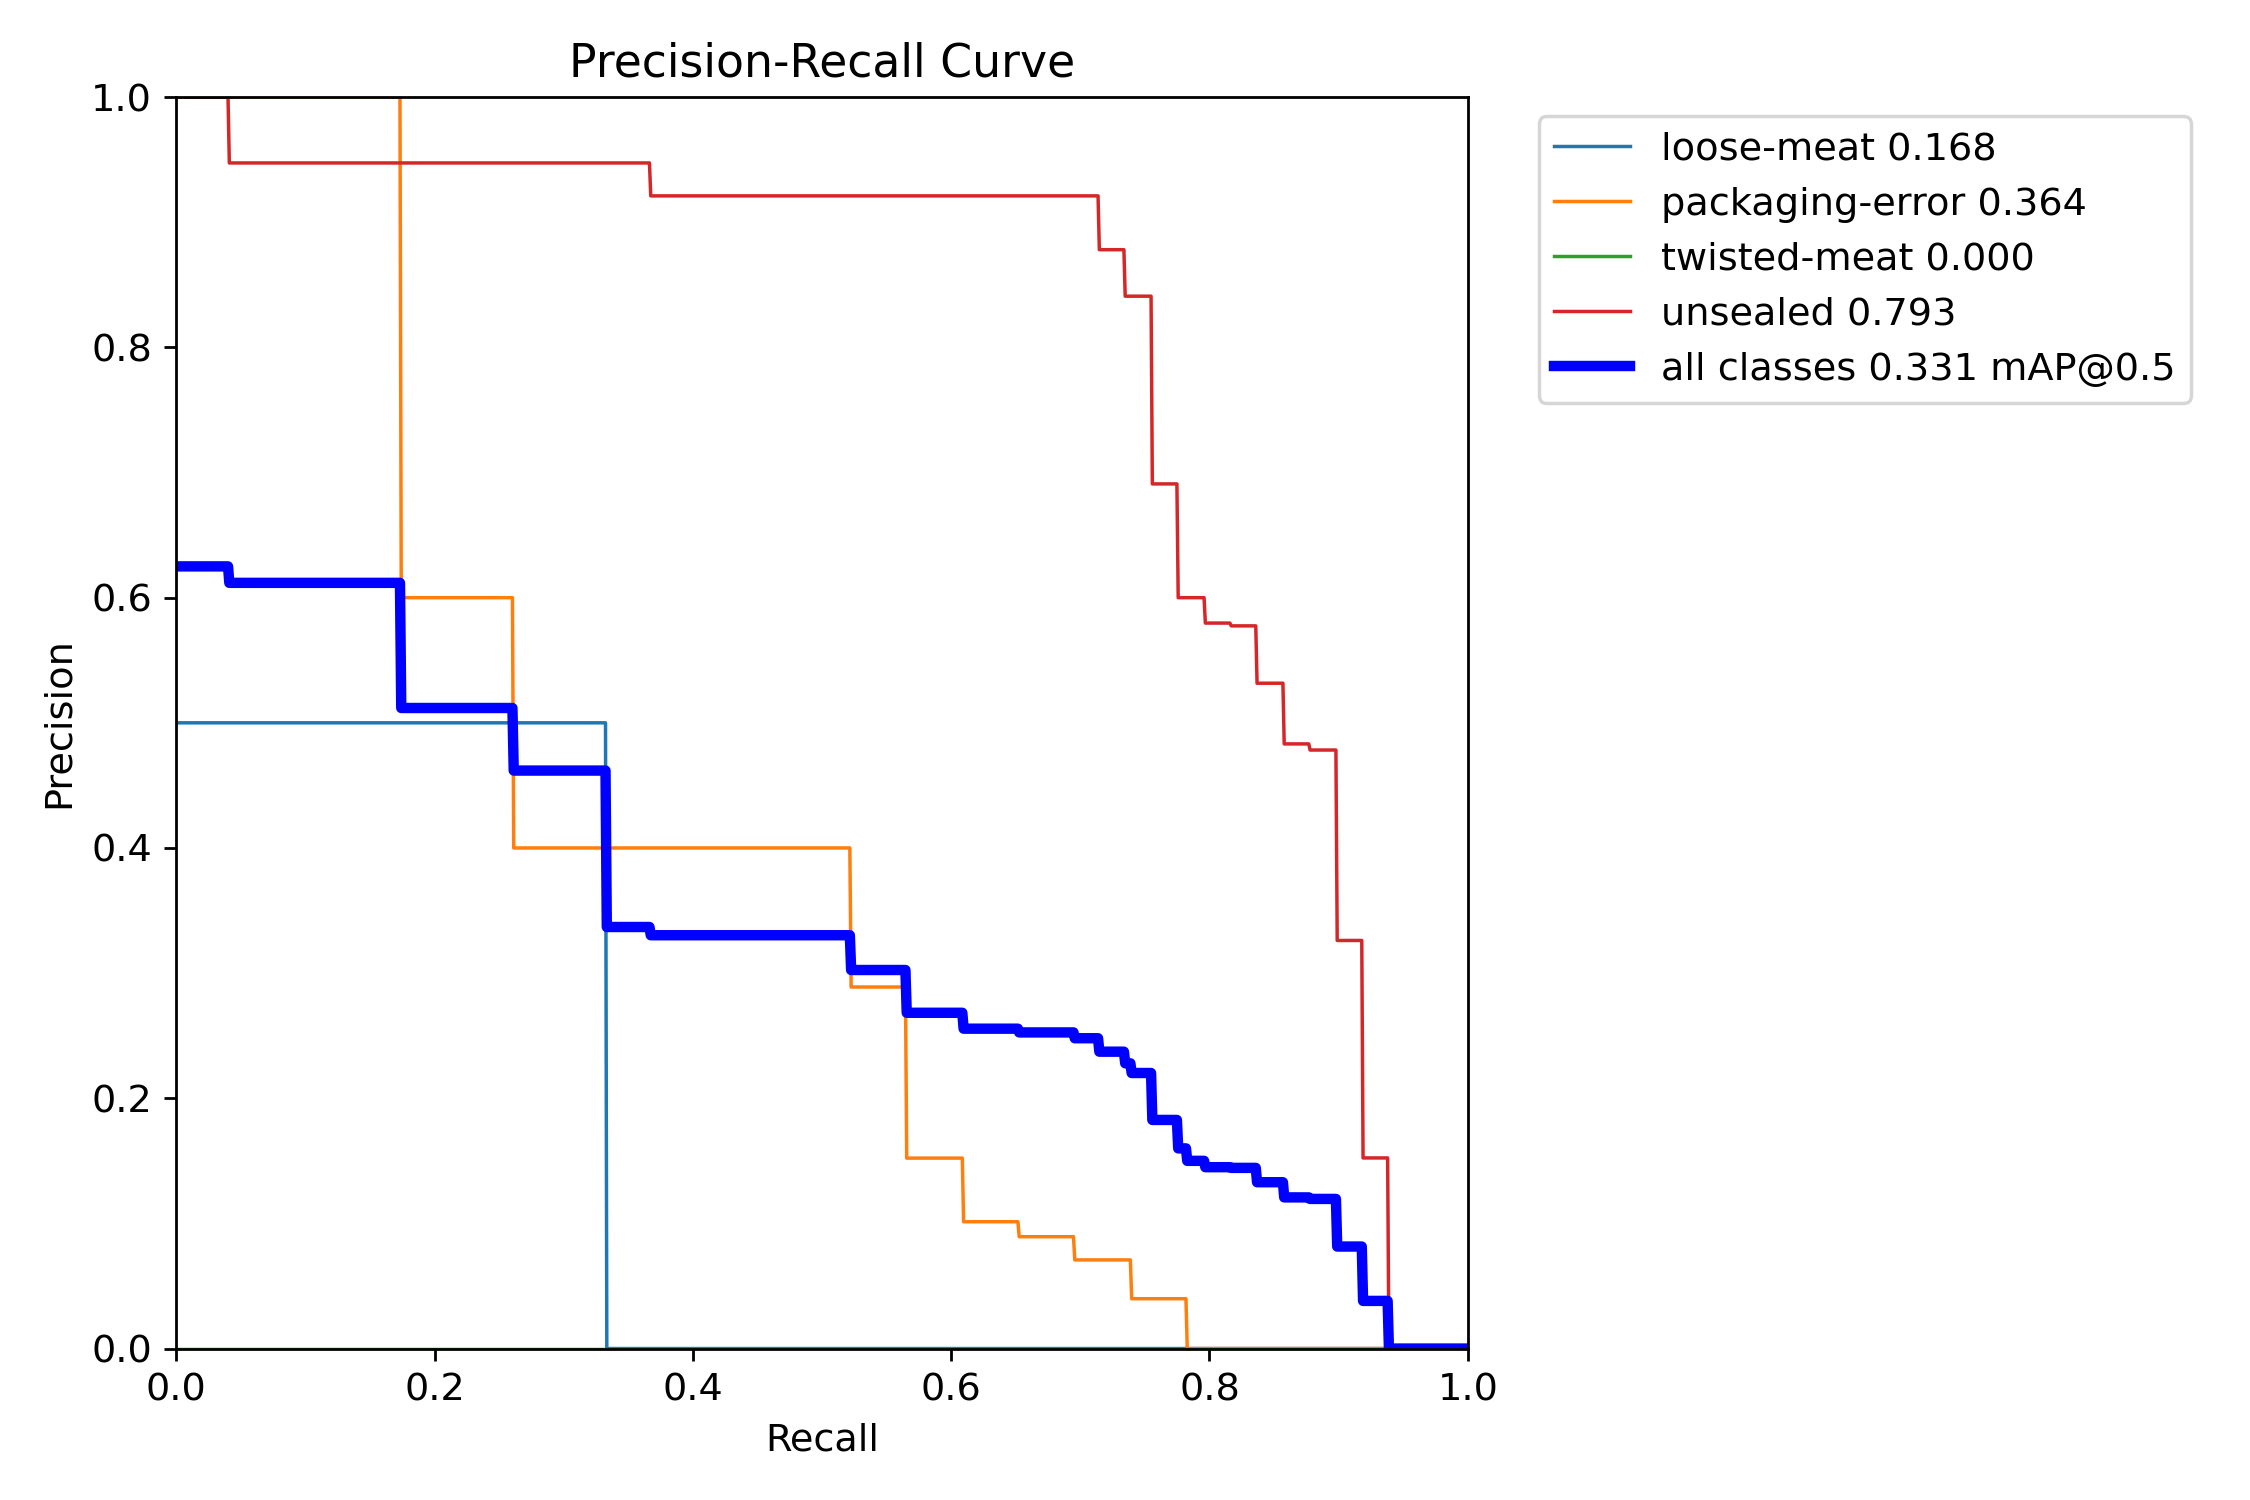

In [15]:
# Ultralytics saves a confusion matrix and PR curves on validation runs
from IPython.display import Image, display
val_dirs = sorted(glob.glob("runs/**/val*", recursive=True), key=os.path.getmtime)
print(val_dirs[-1] if val_dirs else "no val folder found")
for f in ["confusion_matrix_normalized.png", "BoxPR_curve.png"]:
    p = os.path.join(val_dirs[-1], f) if val_dirs else ""
    if os.path.exists(p): display(Image(p, width=600))

## 9. Generate the code docs and test report (commit these to the repo)

In [16]:
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pdoc", "pytest", "pytest-html"])
print(subprocess.run([sys.executable, "-m", "pdoc", "-o", "docs", "src/rasher_qc"], capture_output=True, text=True).stderr)
r = subprocess.run([sys.executable, "-m", "pytest", "-v", "--html=test_report.html", "--self-contained-html"],
                   capture_output=True, text=True)
print(r.stdout[-1500:])


med_label_raises PASSED                   [ 33%]
tests/test_data.py::test_download_requires_key PASSED                    [ 37%]
tests/test_decision.py::test_no_detections_passes PASSED                 [ 41%]
tests/test_decision.py::test_single_confident_defect_fails PASSED        [ 45%]
tests/test_decision.py::test_low_confidence_ignored PASSED               [ 50%]
tests/test_decision.py::test_fail_classes_filter PASSED                  [ 54%]
tests/test_decision.py::test_min_defects PASSED                          [ 58%]
tests/test_decision.py::test_bad_conf_raises[-0.1] PASSED                [ 62%]
tests/test_decision.py::test_bad_conf_raises[1.5] PASSED                 [ 66%]
tests/test_decision.py::test_bad_min_defects_raises PASSED               [ 70%]
tests/test_decision.py::test_binary_metrics_known_values PASSED          [ 75%]
tests/test_decision.py::test_binary_metrics_perfect PASSED               [ 79%]
tests/test_decision.py::test_binary_metrics_errors PASSED             

## 10. Next steps for the report
- Look at false positives and misses on the test split: reflections, occlusion, overlapping meat.
- Download `experiment_results.csv`, `docs/`, `test_report.html` and key figures, and commit them to the repo.
- Note the limitations: tiny test classes, no `wrinkle` in test, 12 PASS trays, one camera setup.